# Rule-based control vs the MILP

A perfect-foresight MILP is not a product. A household buys an inverter that runs a *rule*:
it looks at this interval, decides a setpoint, and never sees tomorrow. This notebook asks
what that costs.

Eight rule-based controllers are executed over a full calendar year and priced through the
**same settlement the MILP is priced through** — the same battery envelope, the same agreed
billing power, the same running excess-power peak, the same `calculate_interval_price`. The
only thing that differs between a rule and the MILP is how the setpoint is chosen, so the
gap between them is a property of the controller and not of the plumbing.

Four axes, crossed:

| axis | values |
|---|---|
| controller | 8 rules, plus a no-battery floor and the whole-year MILP ceiling |
| battery | 5, 10, 20, 30 kWh nameplate |
| household | 8 Fluvius groups (PV / heat pump / EV, in every combination), 5 households each |
| price list | 4 products of one supplier, eligibility enforced |

The headline number is **`Gap_pct`**: the share of the *achievable* saving a controller gives
up. 0 % is the MILP, 100 % is a battery that might as well not be installed. Measured that
way rather than in euros, because the euros at stake differ by an order of magnitude between
a no-PV flat-rate household and a PV household on the dynamic list.

In [8]:
### Imports
import importlib
from pathlib import Path

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

import Data_Loader as dl
import Environment as environment_module
import MILP_Household as milp_module
import Horizon_Comparison as hc
import Rule_Based_Control as rbc

# Dependencies before dependents, so a reload cannot leave two modules
# disagreeing about the battery or the tariff.
dl = importlib.reload(dl)
environment_module = importlib.reload(environment_module)
milp_module = importlib.reload(milp_module)
hc = importlib.reload(hc)
rbc = importlib.reload(rbc)

print("Imports ready.")

Imports ready.


## 1. Configuration

In [ ]:
### Study axes -------------------------------------------------------------
# Read off the modules rather than retyped: the controllers, the capacities and
# the eligibility rules are the study, and a second copy of them here would be a
# second study.
CONTROLLERS = rbc.CONTROLLER_ORDER          # no_battery, 8 rules, milp_full_period
POLICIES = rbc.POLICY_ORDER
CAPACITIES_KWH = rbc.CAPACITIES_KWH
DATASET_GROUPS = hc.DATASET_GROUPS
TARIFF_ORDER = hc.TARIFF_ORDER
PER_GROUP = hc.HOUSEHOLDS_PER_GROUP

### Battery, tariff and solver ----------------------------------------------
# All of these come from MILP_Household via Horizon_Comparison, which is where
# every study in the repository reads them from.
CHARGE_EFFICIENCY = hc.CHARGE_EFFICIENCY
DISCHARGE_EFFICIENCY = hc.DISCHARGE_EFFICIENCY
C_RATE = hc.C_RATE
INVERTER_MAX_KW = hc.INVERTER_MAX_KW
SOC_FRACTION = hc.SOC_FRACTION              # every run starts here; the MILP also ends here
MAX_DAILY_CYCLES = hc.MAX_DAILY_CYCLES
SOC_MIN_FRAC, SOC_MAX_FRAC = hc.SOC_MIN_FRAC, hc.SOC_MAX_FRAC

PRICING_REFERENCE_YEAR = hc.PRICING_REFERENCE_YEAR
PEAK_RESET_MONTHS = hc.PEAK_RESET_MONTHS
SOLVER_GAP_REL = hc.FULL_PERIOD_GAP_REL
SOLVER_TIME_LIMIT_S = hc.FULL_PERIOD_TIME_LIMIT_S

### The one household every illustration is drawn on ------------------------
TRACE_DATASET, TRACE_HOUSEHOLD = "Fluvius_PV", 1
TRACE_TARIFF = "Dinamični"       # the list with the widest spread, so the rules separate
TRACE_CAPACITY_KWH = 10.0

### Caching -----------------------------------------------------------------
RESULTS_DIR = rbc.RESULTS_DIR
RUN_BATCH = False                # True -> re-solve everything (~1.5 h on 10 workers)
N_WORKERS = 10

print(f"{'Controllers':32}{len(POLICIES)} rules + no-battery floor + MILP ceiling")
for name in POLICIES:
    policy = rbc.make_policy(name)
    flag = "" if policy.causal else "   (not deployable: reads the future)"
    print(f"{'  ' + name:32}{policy.label}{flag}")
print(f"{'Capacities':32}{', '.join(f'{c:g}' for c in CAPACITIES_KWH)} kWh nameplate")
print(f"{'Household groups':32}{len(DATASET_GROUPS)} x {PER_GROUP} households")
print(f"{'Price lists':32}{', '.join(TARIFF_ORDER)}")
print(f"{'Jobs':32}{len(rbc.study_jobs())} (household, price list) pairs after eligibility")
print(f"{'Battery':32}C-rate {C_RATE}, inverter {INVERTER_MAX_KW:g} kW, "
      f"eta {CHARGE_EFFICIENCY}/{DISCHARGE_EFFICIENCY}, start SOC {SOC_FRACTION:.0%}")
print(f"{'Envelope':32}SOC {SOC_MIN_FRAC:.0%}-{SOC_MAX_FRAC:.0%}, "
      f"daily cycles {MAX_DAILY_CYCLES}")
print(f"{'Pricing':32}{PRICING_REFERENCE_YEAR} regime, peak reset {PEAK_RESET_MONTHS} month(s)")
print(f"{'Solver':32}gap {SOLVER_GAP_REL}, limit {SOLVER_TIME_LIMIT_S}s")
print(f"{'Agreed power':32}{hc.AGREED_POWER_TAG}")

Controllers                     8 rules + no-battery floor + MILP ceiling
  self_consumption              Self-consumption
  fixed_schedule                Fixed schedule
  delayed_pv_charge             Delayed PV charge
  price_threshold               Price threshold
  price_rank_daily              Day-ahead price rank
  peak_shaving                  Peak shaving
  self_consumption_peak_shaving Self-consumption + peak shaving
  price_oracle                  Price threshold (foresight)   (not deployable: reads the future)
Capacities                      5, 10, 20, 30 kWh nameplate
Household groups                8 x 5 households
Price lists                     Dinamični, Aktivni, Redni 1T, Redni 2T
Jobs                            140 (household, price list) pairs after eligibility
Battery                         C-rate 0.5, inverter 11 kW, eta 0.95/0.95, start SOC 50%
Envelope                        SOC 0%-100%, daily cycles None
Pricing                         2026 regime, peak reset 1

In [10]:
### Shared chart styling
import importlib
import Plotting_Functions as pf   # one module decides style, size and export

# Reloaded like the repo modules in the imports cell: `import` returns whatever
# the kernel cached the first time, so editing Plotting_Functions and re-running
# this cell would otherwise keep the old module -- which shows up as a TypeError
# about an argument that does exist in the file.
pf = importlib.reload(pf)

# titles=False: an IEEE figure carries no title of its own -- the caption below
# it, set in the article, is the title. The text is not lost, it goes into each
# export's SOURCE.md as the caption to use.
pf.use(subdir="rbc_vs_milp", titles=False)
from Plotting_Functions import INK, INK_2, MUTED, SURFACE, SERIES, EUR, PCT, finish

# ---------------------------------------------------------------------------
# What the colour channel means, and it means only this:
#
#   hue      what the controller READS. Three families and nothing else:
#            green  the roof      -- only ever moves the household's own PV
#            blue   the price     -- trades with the grid on a time or price signal
#            orange the meter     -- trades to hold the grid draw down
#            ink    a reference   -- the no-battery floor and the MILP ceiling
#   shade    position inside the family, light -> dark. It is NOT rank: adding
#            or dropping a controller must not repaint the survivors.
#
# Ten controllers is far too many for ten hues, and the family is the question
# every chapter actually asks. Identity is never colour-alone -- every bar is
# labelled with its controller name.
#
# The hues are pf.SERIES, the shared palette; which FAMILY wears which hue is
# this study's semantics and stays here.
FAMILY_COLOR = {"roof": SERIES[2], "price": SERIES[0], "meter": SERIES[1],
                "reference": INK_2}
FAMILY_LABEL = {"roof": "reads the roof", "price": "reads the price",
                "meter": "reads the meter", "reference": "reference"}
FAMILY = {
    "no_battery": "reference",
    "self_consumption": "roof",
    "delayed_pv_charge": "roof",
    "fixed_schedule": "price",
    "price_threshold": "price",
    "price_rank_daily": "price",
    "price_oracle": "price",
    "peak_shaving": "meter",
    "self_consumption_peak_shaving": "meter",
    "milp_full_period": "reference",
}
CONTROLLER_LABEL = {"no_battery": "No battery", "milp_full_period": "MILP (whole year)"}
CONTROLLER_LABEL.update({name: rbc.make_policy(name).label for name in POLICIES})


def controller_color(name):
    """Family hue, shaded by position WITHIN the family, never by rank."""
    family = FAMILY.get(name, "reference")
    members = [c for c in CONTROLLERS if FAMILY.get(c) == family]
    if len(members) < 2:
        return FAMILY_COLOR[family]
    t = members.index(name) / (len(members) - 1)
    return pf.mix(FAMILY_COLOR[family], "#ffffff", 0.45 * (1.0 - t))


def family_legend(ax, families=("roof", "price", "meter", "reference"), **kw):
    """One swatch per family: the only categorical question the charts ask."""
    return pf.key_legend(ax, [Patch(facecolor=FAMILY_COLOR[f], label=FAMILY_LABEL[f])
                              for f in families], **kw)


def group_label(dataset):
    """Household type as a chart label: the `Fluvius` prefix carries no meaning."""
    return "basic" if dataset == "Fluvius" else str(dataset).replace("Fluvius_", "")


def panel_label(ax, text):
    """Heading for one panel of a multi-panel figure.

    A DATA label, not the figure's caption: it says which of the three rows the
    reader is looking at, so it is set directly rather than through `finish` and
    survives `titles=False`.
    """
    ax.set_title(text, color=INK, fontsize=11)
    return ax


def bar_labels(ax, bars, values, fmt="{:.0f}", pad=0.01, horizontal=True):
    """Direct labels on the data end, in ink rather than in the series colour."""
    span = max(abs(v) for v in values) or 1.0
    for bar, value in zip(bars, values):
        if not np.isfinite(value):
            continue
        if horizontal:
            ax.text(value + np.sign(value or 1) * pad * span, bar.get_y() + bar.get_height() / 2,
                    fmt.format(value), va="center",
                    ha="left" if value >= 0 else "right", fontsize=9, color=INK_2)
        else:
            ax.text(bar.get_x() + bar.get_width() / 2, value + np.sign(value or 1) * pad * span,
                    fmt.format(value), ha="center",
                    va="bottom" if value >= 0 else "top", fontsize=9, color=INK_2)


print("Chart styling ready.")

Chart styling ready.


## 2. The controllers

Every rule sees the same three things a real inverter sees: the household load and the roof
this interval, the delivered price of a kWh, and the calendar. None of them sees the future,
with one deliberate exception.

`price_oracle` is `price_threshold` with its window pointed **forward** instead of backward —
the same quantiles, the same breakeven gate, the same everything else. It is not a
recommendation and could not be installed; it is there so that the difference between the two
isolates what foresight alone is worth to a threshold rule, with the shape of the rule held
fixed.

It is worth knowing in advance that the difference is small, and that it is not even always
positive (verification 4). A threshold rule is a heuristic: better information moves where its
thresholds sit, but it cannot make the logic behind them any less crude.

In [11]:
roster = pd.DataFrame([
    {"Controller": name,
     "Family": FAMILY_LABEL[FAMILY[name]],
     "Causal": "yes" if rbc.make_policy(name).causal else "NO",
     "Reads": reads,
     "What it does": what}
    for name, reads, what in [
        ("self_consumption", "roof",
         "Charge the PV surplus, discharge into the deficit. Never trades with the grid."),
        ("delayed_pv_charge", "roof, yesterday's roof",
         "Throttles the morning so the pack still has headroom for the midday PV peak. "
         "Persistence forecast."),
        ("fixed_schedule", "clock",
         "Charge 01-05 local, discharge 18-22 local, soak surplus in between. No price input."),
        ("price_threshold", "price, trailing 7 d",
         "Buy under the 25th percentile of recent delivered rates, sell over the 75th, "
         "gated on round-trip breakeven."),
        ("price_rank_daily", "price, day-ahead",
         "Rank the day's 96 intervals, pair cheapest with dearest while the pair clears "
         "round-trip losses."),
        ("peak_shaving", "meter, tariff",
         "Hold the draw under min(agreed power, own 98th percentile OF THE METER). Stands "
         "down once the month's peak is sunk."),
        ("self_consumption_peak_shaving", "roof, meter, tariff",
         "Self-consumption over a reserve sized to the worst daily shave the trailing window "
         "demanded."),
        ("price_oracle", "price, FORWARD 7 d",
         "price_threshold with the window reversed. Diagnostic only."),
    ]
]).set_index("Controller").reindex(POLICIES)
display(roster)

,Family,Causal,Reads,What it does
Controller,,,,
self_consumption,reads the roof,yes,roof,"Charge the PV surplus, discharge into the defi..."
fixed_schedule,reads the price,yes,clock,"Charge 01-05 local, discharge 18-22 local, soa..."
delayed_pv_charge,reads the roof,yes,"roof, yesterday's roof",Throttles the morning so the pack still has he...
price_threshold,reads the price,yes,"price, trailing 7 d",Buy under the 25th percentile of recent delive...
price_rank_daily,reads the price,yes,"price, day-ahead","Rank the day's 96 intervals, pair cheapest wit..."
peak_shaving,reads the meter,yes,"meter, tariff","Hold the draw under min(agreed power, own 98th..."
self_consumption_peak_shaving,reads the meter,yes,"roof, meter, tariff",Self-consumption over a reserve sized to the w...
price_oracle,reads the price,NO,"price, FORWARD 7 d",price_threshold with the window reversed. Diag...


### The rules on one summer day

One household, one day, one pack. The top panel is the price the rules are deciding against,
the middle one is the household they are controlling, and the bottom one is where each of them
put the charge. The MILP is the dashed trace — the only one that was allowed to see how the day
ends before deciding how it starts.

In [12]:
TRACE_DAY = "2024-06-12"          # a clear summer day: PV, evening peak, wide SIPX spread

trace_data = hc.load_user(TRACE_HOUSEHOLD, TRACE_DATASET)
trace_env = hc.build_env(trace_data, capacity_kwh=TRACE_CAPACITY_KWH, tariff=TRACE_TARIFF)
trace_sig = rbc.build_signals(trace_env)

traces = {}
for name in POLICIES:
    out = rbc.run_policy(trace_env, rbc.make_policy(name), signals=trace_sig, keep_traces=True)
    traces[name] = {"soc": out["_soc_trace"], "setpoint": out["_setpoints"]}

milp = hc.run_strategy(trace_env, "period", "block", solver=hc.full_period_solver())
traces["milp_full_period"] = {"soc": milp["_soc_trace"], "setpoint": None}

print(f"{TRACE_DATASET} #{TRACE_HOUSEHOLD} | {TRACE_TARIFF} | {TRACE_CAPACITY_KWH:g} kWh")

Fluvius_PV #1 | Dinamični | 10 kWh


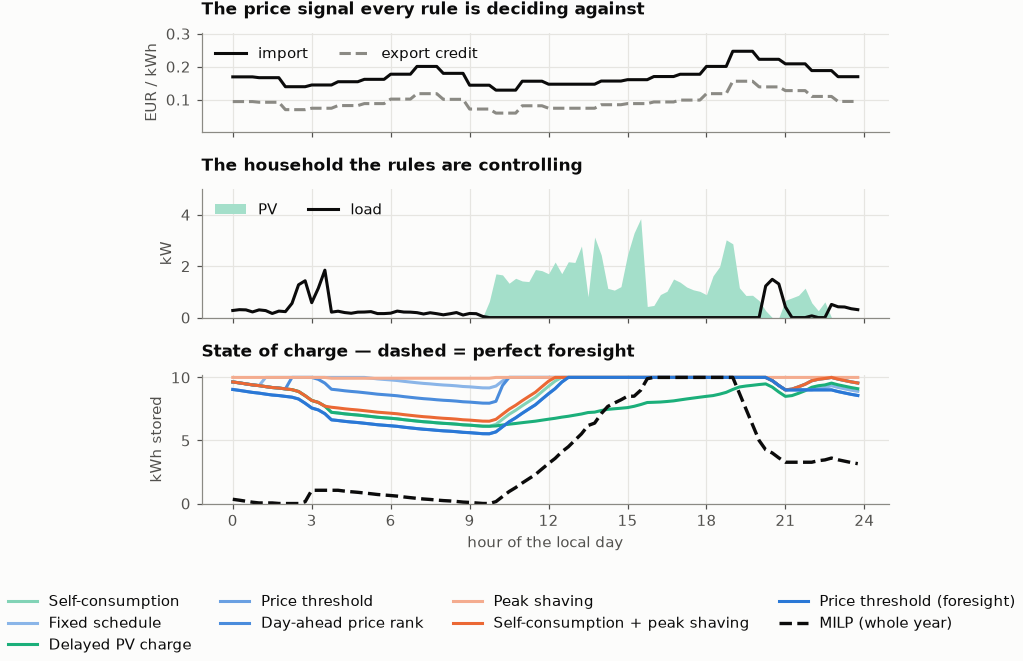

In [13]:
# Sliced on the LOCAL day. The Fluvius stamps carry a `Z` suffix but are
# Brussels-local, so a window cut on the raw index starts two hours off and the
# hour axis would wrap mid-chart.
_, days_sorted, _ = milp_module.day_calendar(trace_env.dataset.index[:trace_sig.n_steps])
day = np.asarray(trace_sig.day_steps[days_sorted.index(pd.Timestamp(TRACE_DAY).date())])
hours = trace_sig.local_hour[day]
assert np.all(np.diff(hours) > 0), "the local day did not come out monotone"

# Three stacked rows sharing the hour axis: one figure, because the point is
# that the same day drives all three.
fig, axes = plt.subplots(3, 1, figsize=pf.figsize(ratio=0.91), sharex=True,
                         gridspec_kw={"height_ratios": [1.0, 1.3, 1.3]})

# --- what the day costs ----------------------------------------------------
ax = axes[0]
ax.plot(hours, trace_sig.import_rate[day], lw=2, color=INK, label="import")
ax.plot(hours, trace_sig.export_credit[day], lw=2, color=MUTED, ls="--", label="export credit")
ax.margins(y=0.30)                       # headroom, so the legend never sits on a line
ax.legend(loc="upper left", ncols=2)
panel_label(ax, "The price signal every rule is deciding against")
ax.set_ylabel("EUR / kWh")

# --- the household ---------------------------------------------------------
ax = axes[1]
ax.fill_between(hours, 0, trace_sig.generation[day] / trace_sig.hours,
                color=pf.mix(FAMILY_COLOR["roof"], "#ffffff", 0.6), lw=0, label="PV")
ax.plot(hours, trace_sig.consumption[day] / trace_sig.hours, lw=2, color=INK, label="load")
ax.margins(y=0.30)
ax.set_ylim(bottom=0)                    # a negative kW here would be a drawing artefact
ax.legend(loc="upper left", ncols=2)
panel_label(ax, "The household the rules are controlling")
ax.set_ylabel("kW")

# --- where the charge sits -------------------------------------------------
ax = axes[2]
for name in POLICIES:
    ax.plot(hours, traces[name]["soc"][day], lw=2, color=controller_color(name),
            label=CONTROLLER_LABEL[name])
ax.plot(hours, traces["milp_full_period"]["soc"][day], lw=2.2, ls="--", color=INK,
        label=CONTROLLER_LABEL["milp_full_period"])
ax.set_ylim(0, TRACE_CAPACITY_KWH * 1.02)
ax.set_xticks(range(0, 25, 3))
panel_label(ax, "State of charge — dashed = perfect foresight")
ax.set_xlabel("hour of the local day")
ax.set_ylabel("kWh stored")

# Ten traces will not fit beside the data, so the keys go under the figure --
# chart_frame measures the rows they need before it lays the axes out.
pf.chart_frame(fig, f"One day on {TRACE_TARIFF}: what every rule sees and what it does",
               handles=ax.get_legend_handles_labels()[0], ncol=4)
pf.show(fig, "trace_day", layout="frame")

## 3. The batch

One CSV per (household, price list), every capacity and every controller inside it. Rows carry
the ratchet reset and agreed-power rule they were priced under, and `collect_results` drops any
that were written under a superseded one — a bill computed under a different network charge is
a different quantity, not an older one.

Set `RUN_BATCH = True` in the configuration cell to recompute. It takes roughly an hour and a
half on ten workers, almost all of it in the MILP arm; the eight rules together cost about
twelve seconds per household.

In [14]:
if RUN_BATCH:
    rbc.run_batch(n_workers=N_WORKERS)

raw = rbc.collect_results()
if raw.empty:
    raise FileNotFoundError(
        f"No results in {RESULTS_DIR}. Set RUN_BATCH = True, or run\n"
        f"    .venv/bin/python Rule_Based_Control.py --workers {N_WORKERS}"
    )

# A unit is one (household, price list, capacity) that carries BOTH references.
# A job still mid-flight has some controllers and not others, and averaging over
# a partial unit would compare a controller against a missing optimum.
complete = (
    raw.groupby(rbc.KEY_COLUMNS)["Controller"]
    .transform(lambda s: set(CONTROLLERS).issubset(set(s)))
)
if not complete.all():
    print(f"dropped {int((~complete).sum())} rows from "
          f"{raw.loc[~complete, rbc.KEY_COLUMNS].drop_duplicates().shape[0]} "
          f"incomplete units still being solved")
results = raw[complete].reset_index(drop=True)

scored = rbc.score(results)
# Redni 2T is a no-PV-only product, so it may never enter a mean taken ACROSS
# household groups: that would compare who is allowed to sign what, not which
# controller is better. Chapter 7 reports it on its own.
cross = rbc.cross_group_frame(scored)

units = results[rbc.KEY_COLUMNS].drop_duplicates()
print(f"{len(results):,} rows | {len(units):,} complete units "
      f"({units['Dataset'].nunique()} groups x {units['Household'].nunique()} households "
      f"x {units['Tariff'].nunique()} lists x {units['Capacity_kWh'].nunique()} capacities)")
print(f"peak reset {sorted(set(results['Peak_Reset']))} | "
      f"agreed power {sorted(set(results['Agreed_Power']))}")

140 jobs x 4 capacities x 10 controllers on 10 workers
  [Fluvius 1 | Aktivni] checkpoint written under peak reset ['1m'] / agreed power ['prev1m_top5_cyclic_unbounded_dispatch'] / settlement ['as_converged']; recomputing from scratch
  [Fluvius 1 | Dinamični] checkpoint written under peak reset ['1m'] / agreed power ['prev1m_top5_cyclic_unbounded_dispatch'] / settlement ['as_converged']; recomputing from scratch
  [Fluvius 2 | Dinamični] checkpoint written under peak reset ['1m'] / agreed power ['prev1m_top5_cyclic_unbounded_dispatch'] / settlement ['as_converged']; recomputing from scratch
  [Fluvius 1 | Redni 1T] checkpoint written under peak reset ['1m'] / agreed power ['prev1m_top5_cyclic_unbounded_dispatch'] / settlement ['as_converged']; recomputing from scratch
  [Fluvius 2 | Redni 1T] checkpoint written under peak reset ['1m'] / agreed power ['prev1m_top5_cyclic_unbounded_dispatch'] / settlement ['as_converged']; recomputing from scratch
  [Fluvius 2 | Redni 2T] checkpoint wri

## 4. Which controller

`Gap_pct` is the share of the achievable saving a controller gives up, where "achievable" is
what the whole-year MILP actually captures on that same household, list and pack. The mean is
taken over units; `Gap_pct_pooled` weights each unit by the euros at stake instead, which is
the honest figure when one household's battery is worth 500 EUR a year and another's is worth
five.

Redni 2T is excluded from every cross-group figure in this chapter — see chapter 7.

In [15]:
ranking, _ = rbc.summarize(cross, by=["Controller"])
display(
    ranking[["Units", "Gap_pct", "Gap_pct_pooled", "Worst_Gap_pct", "Best_Gap_pct",
             "Savings_EUR", "Gap_EUR", "Cycles", "Grid_Charged_kWh"]]
    .rename(columns={"Savings_EUR": "Saving_EUR/a", "Grid_Charged_kWh": "GridChg_kWh/a"})
    .round(1)
)

,Units,Gap_pct,Gap_pct_pooled,Worst_Gap_pct,Best_Gap_pct,Saving_EUR/a,Gap_EUR,Cycles,GridChg_kWh/a
Controller,,,,,,,,,
no_battery,480,100.0,100.0,100.0,100.0,0.0,398.2,0.0,0.0
self_consumption,480,82.7,84.0,100.6,24.1,63.6,334.5,45.7,0.0
fixed_schedule,480,84.7,84.8,152.6,33.4,60.4,337.8,213.3,2764.1
delayed_pv_charge,480,83.9,85.3,100.6,24.2,58.6,339.6,44.2,0.0
price_threshold,480,75.8,75.1,100.6,17.6,99.3,298.8,126.1,1538.5
price_rank_daily,480,68.7,68.5,100.6,24.1,125.3,272.9,149.9,1696.1
peak_shaving,480,79.0,85.1,100.8,29.9,59.2,339.0,22.1,211.6
self_consumption_peak_shaving,480,71.0,77.0,100.6,11.9,91.4,306.8,49.1,181.6
price_oracle,480,74.6,73.3,100.6,18.5,106.5,291.7,131.2,1614.2


findfont: Failed to find font weight semibold, now using 700.


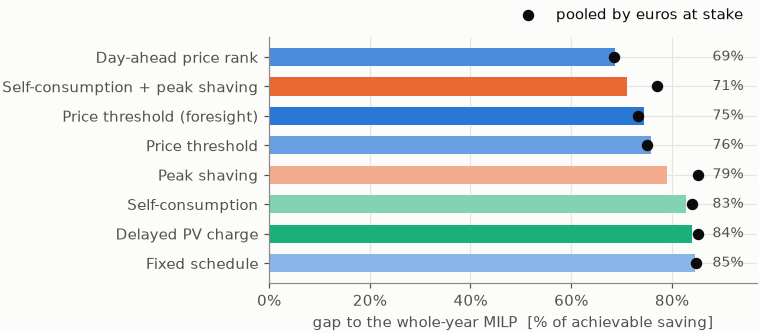

In [16]:
rules = [c for c in POLICIES]
gap = ranking.loc[rules, "Gap_pct"]
pooled = ranking.loc[rules, "Gap_pct_pooled"]
order = gap.sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.46))
y = np.arange(len(order))
bars = ax.barh(y, gap[order], height=0.62,
               color=[controller_color(c) for c in order])
# The pooled figure as a tick, so the euro-weighted answer sits beside the
# per-household one instead of in a second chart with a second scale.
ax.scatter(pooled[order], y, s=42, color=INK, zorder=3, label="pooled by euros at stake")
ax.set_yticks(y, [CONTROLLER_LABEL[c] for c in order])
# A label COLUMN rather than a label on each data end: the pooled dots sit close
# to the bar ends and the two would collide on the rules that rank best.
label_x = float(gap.max()) * 1.04
ax.set_xlim(0, label_x * 1.10)
for row, value in zip(y, gap[order]):
    ax.text(label_x, row, f"{value:.0f}%", va="center", ha="left",
            fontsize=9, color=INK_2)
# Outside the axes: inside, the legend's sample dot reads as a data point.
ax.legend(loc="lower right", bbox_to_anchor=(1.0, 1.0))
finish(ax, title="How much of the achievable saving each rule gives up",
       xlabel="gap to the whole-year MILP  [% of achievable saving]", xfmt=PCT)
pf.show(fig, "gap_by_rule")

### The same question per price list

A controller is not good or bad in the abstract: it is good or bad against a price signal. A
rule that never trades with the grid cannot lose on a flat list and cannot win on a volatile
one.

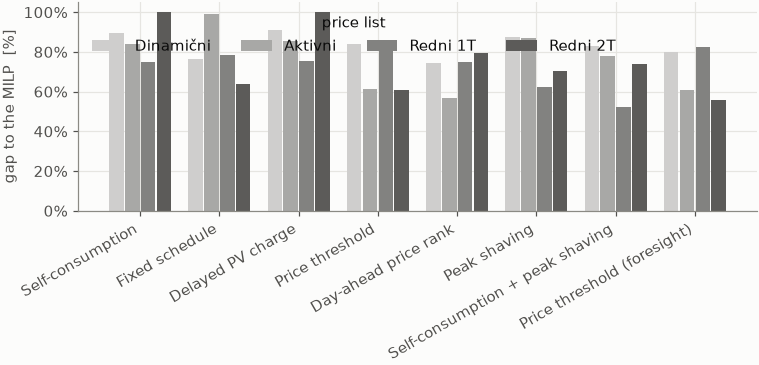

Tariff,Dinamični,Aktivni,Redni 1T,Redni 2T
Controller,,,,
self_consumption,89.7,83.8,74.7,100.1
fixed_schedule,76.6,99.0,78.4,63.7
delayed_pv_charge,90.9,85.6,75.4,100.1
price_threshold,84.0,61.3,82.3,61.0
price_rank_daily,74.4,57.0,74.7,79.5
peak_shaving,87.3,87.2,62.6,70.3
self_consumption_peak_shaving,82.7,78.2,52.2,74.1
price_oracle,80.1,61.1,82.5,55.8


In [17]:
by_tariff, _ = rbc.summarize(scored, by=["Tariff", "Controller"])
table = (by_tariff["Gap_pct"].unstack("Tariff")
         .reindex(index=POLICIES, columns=TARIFF_ORDER))

fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.50))
width = 0.8 / len(TARIFF_ORDER)
x = np.arange(len(POLICIES))
for k, tariff in enumerate(TARIFF_ORDER):
    values = table[tariff].to_numpy(dtype=float)
    offset = (k - (len(TARIFF_ORDER) - 1) / 2) * width
    ax.bar(x + offset, values, width=width * 0.92,
           color=pf.mix(INK_2, "#ffffff", 0.72 - 0.22 * k), label=tariff)
ax.set_xticks(x, [CONTROLLER_LABEL[c] for c in POLICIES], rotation=30, ha="right")
ax.legend(loc="upper left", ncols=len(TARIFF_ORDER), title="price list")
finish(ax, title="The gap depends on what the price signal offers",
       ylabel="gap to the MILP  [%]", yfmt=PCT)
pf.show(fig, "gap_by_price_list")
display(table.round(1))

### The best and the worst household

A mean hides the two cases worth looking at. Both are drawn only from units where there was a
real prize to compete for: on a household whose whole achievable saving is four euros, a gap of
several hundred percent is rounding, not a controller failing, and those units would otherwise
occupy the entire "worst" half of the table.

In [18]:
# A percentage is only worth reading where there was a prize to win. Units whose
# whole achievable saving is a few euros produce enormous gaps out of rounding,
# and they would otherwise fill the "worst" half of this table every time.
MEANINGFUL_PRIZE_EUR = 25.0

best_rule = ranking.loc[rules, "Gap_pct"].idxmin()
focus = (cross[(cross["Controller"] == best_rule)
               & (cross["Achievable_EUR"] >= MEANINGFUL_PRIZE_EUR)]
         .dropna(subset=["Gap_pct"]))
extremes = pd.concat([focus.nsmallest(3, "Gap_pct"), focus.nlargest(3, "Gap_pct")])
print(f"{len(focus)} of {int((cross['Controller'] == best_rule).sum())} units had at "
      f"least {MEANINGFUL_PRIZE_EUR:.0f} EUR/a of achievable saving to compete for")

print(f"Best rule overall: {CONTROLLER_LABEL[best_rule]} "
      f"({ranking.loc[best_rule, 'Gap_pct']:.0f}% mean gap)\n")
display(
    extremes[["Dataset", "Household", "Tariff", "Capacity_kWh", "Gap_pct",
              "Savings_EUR", "Achievable_EUR", "No_Battery_EUR", "Grid_Charged_kWh"]]
    .assign(Dataset=lambda d: d["Dataset"].map(group_label))
    .round(1).set_index(["Dataset", "Household", "Tariff", "Capacity_kWh"])
)

lo, hi = extremes.iloc[0], extremes.iloc[-1]
print(f"best  {group_label(lo.Dataset)} #{int(lo.Household)} on {lo.Tariff} at "
      f"{lo.Capacity_kWh:g} kWh: captures {100 - lo.Gap_pct:.0f}% of a "
      f"{lo.Achievable_EUR:,.0f} EUR/a prize")
print(f"worst {group_label(hi.Dataset)} #{int(hi.Household)} on {hi.Tariff} at "
      f"{hi.Capacity_kWh:g} kWh: captures {100 - hi.Gap_pct:.0f}% of a "
      f"{hi.Achievable_EUR:,.0f} EUR/a prize")

480 of 480 units had at least 25 EUR/a of achievable saving to compete for
Best rule overall: Day-ahead price rank (69% mean gap)



Gap_pct  Savings_EUR  Achievable_EUR  \
Dataset Household Tariff   Capacity_kWh                                         
PV      3         Redni 1T 30.0             24.1        101.2           133.4   
                           20.0             24.3        100.1           132.3   
                           10.0             25.9         97.1           131.1   
basic   5         Redni 1T 30.0            100.6         -0.2            33.3   
                           20.0            100.4         -0.1            33.3   
HP      3         Redni 1T 30.0            100.3         -0.2            80.3   

                                         No_Battery_EUR  Grid_Charged_kWh  
Dataset Household Tariff   Capacity_kWh                                    
PV      3         Redni 1T 30.0                   109.2               0.0  
                           20.0                   109.2               0.0  
                           10.0                   109.2               0.0  
basic   5         Redni 1T 30.0                   174.3               0.0  
                           20.0                   174.3               0.0  
HP      3         Redni 1T 30.0                  1161.9               0.0

best  PV #3 on Redni 1T at 30 kWh: captures 76% of a 133 EUR/a prize
worst HP #3 on Redni 1T at 30 kWh: captures -0% of a 80 EUR/a prize


## 5. Battery size

Does a rule fall further behind as the pack grows? It should. A bigger battery is a longer
lever on the future, and a controller that decides one interval at a time has no more future
to pull on than it had at 5 kWh.

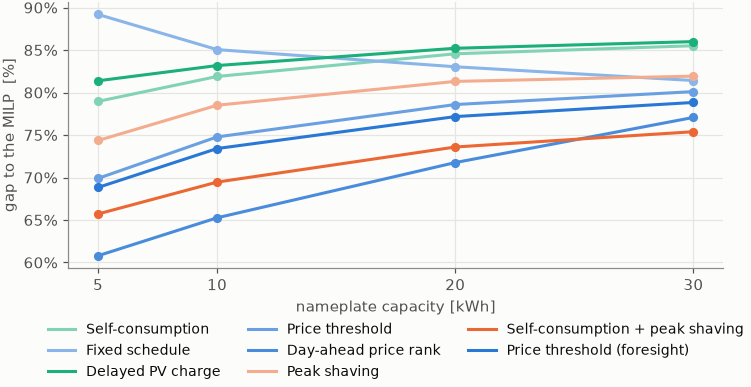

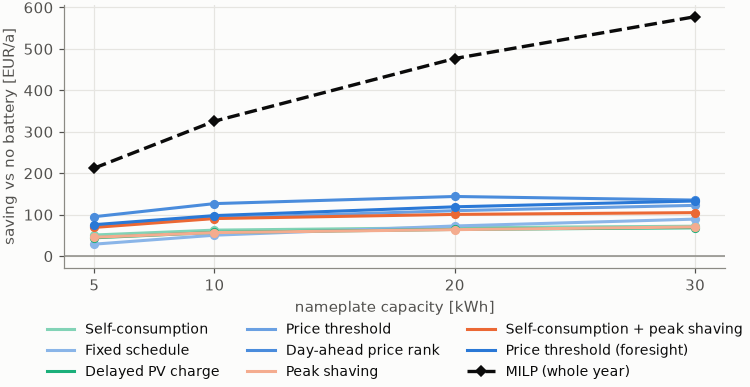

Controller,self_consumption,fixed_schedule,delayed_pv_charge,price_threshold,price_rank_daily,peak_shaving,self_consumption_peak_shaving,price_oracle
Capacity_kWh,,,,,,,,
5.0,79.0,89.2,81.4,69.9,60.8,74.4,65.7,68.8
10.0,81.9,85.1,83.2,74.8,65.3,78.5,69.5,73.4
20.0,84.6,83.0,85.2,78.6,71.8,81.3,73.6,77.2
30.0,85.5,81.4,86.0,80.1,77.1,81.9,75.4,78.8


In [19]:
by_capacity, _ = rbc.summarize(cross, by=["Capacity_kWh", "Controller"])
gap_by_cap = by_capacity["Gap_pct"].unstack("Controller").reindex(columns=POLICIES)
save_by_cap = (rbc.summarize(cross, by=["Capacity_kWh", "Controller"])[0]["Savings_EUR"]
               .unstack("Controller").reindex(columns=POLICIES))
milp_saving = (cross[cross["Controller"] == "milp_full_period"]
               .groupby("Capacity_kWh")["Savings_EUR"].mean())

# Two figures rather than two panels: half of \textwidth is \columnwidth, and
# eight labelled lines do not read at that width. Same cell, one pf.show each.
# Four of the eight lines are blue, so the family legend alone cannot identify a
# line -- each figure carries the full controller key underneath.
CONTROLLER_KEYS = [Line2D([], [], color=controller_color(c), lw=2,
                          label=CONTROLLER_LABEL[c]) for c in POLICIES]

fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.52))
for name in POLICIES:
    ax.plot(gap_by_cap.index, gap_by_cap[name], marker="o", ms=5, lw=2,
            color=controller_color(name), label=CONTROLLER_LABEL[name])
ax.set_xticks(CAPACITIES_KWH)
finish(ax, title="The gap widens with the pack", xlabel="nameplate capacity [kWh]",
       ylabel="gap to the MILP  [%]", yfmt=PCT)
pf.key_legend(ax, CONTROLLER_KEYS, ncol=3, fontsize=9)
pf.show(fig, "gap_vs_capacity")

fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.52))
for name in POLICIES:
    ax.plot(save_by_cap.index, save_by_cap[name], marker="o", ms=5, lw=2,
            color=controller_color(name))
ax.plot(milp_saving.index, milp_saving, lw=2.2, ls="--", color=INK, marker="D", ms=5,
        label=CONTROLLER_LABEL["milp_full_period"])
ax.axhline(0, color=MUTED, lw=1)
ax.set_xticks(CAPACITIES_KWH)
finish(ax, title="What each rule actually earns", xlabel="nameplate capacity [kWh]",
       ylabel="saving vs no battery [EUR/a]", yfmt=EUR)
pf.key_legend(ax, CONTROLLER_KEYS
              + [Line2D([], [], color=INK, lw=2.2, ls="--", marker="D", ms=5,
                        label=CONTROLLER_LABEL["milp_full_period"])],
              ncol=3, fontsize=9)
pf.show(fig, "saving_vs_capacity")
display(gap_by_cap.round(1))

## 6. Household type

Eight Fluvius groups: a plain load, and every combination of a PV roof, a heat pump and an
electric vehicle. What a controller can do depends on what the household gives it to work
with — a roof to store, or a big flexible load to move.

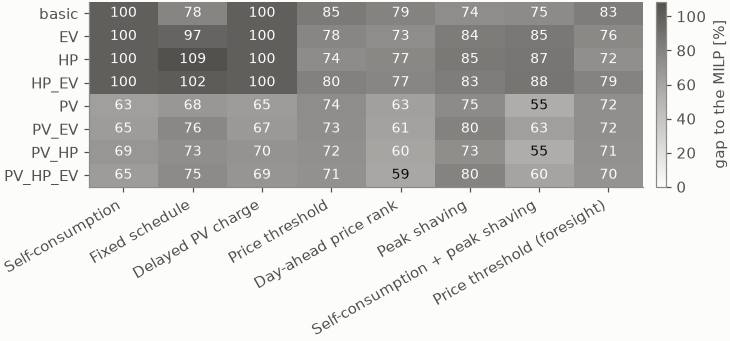

In [20]:
by_group, _ = rbc.summarize(cross, by=["Dataset", "Controller"])
heat = (by_group["Gap_pct"].unstack("Controller")
        .reindex(index=[g for g in DATASET_GROUPS], columns=POLICIES))

fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.47))
values = heat.to_numpy(dtype=float)
# One hue, light -> dark: this panel encodes magnitude, not identity. The ramp
# is NEUTRAL rather than a family hue -- its columns span all three families,
# and a family hue here would read as a claim about which family a cell belongs
# to.
image = ax.imshow(values, aspect="auto", cmap=pf.ramp(INK_2, "gap"), vmin=0,
                  vmax=float(np.nanmax(values)))
ax.set_xticks(range(len(POLICIES)), [CONTROLLER_LABEL[c] for c in POLICIES],
              rotation=30, ha="right")
ax.set_yticks(range(len(heat.index)), [group_label(g) for g in heat.index])
ax.grid(False)
mid = float(np.nanmax(values)) * 0.55
for i in range(values.shape[0]):
    for j in range(values.shape[1]):
        v = values[i, j]
        if not np.isfinite(v):
            continue
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=9,
                color=SURFACE if v > mid else INK)
fig.colorbar(image, ax=ax, label="gap to the MILP [%]", pad=0.02)
finish(ax, title="Gap to the MILP by household type")
pf.show(fig, "gap_by_household_type")

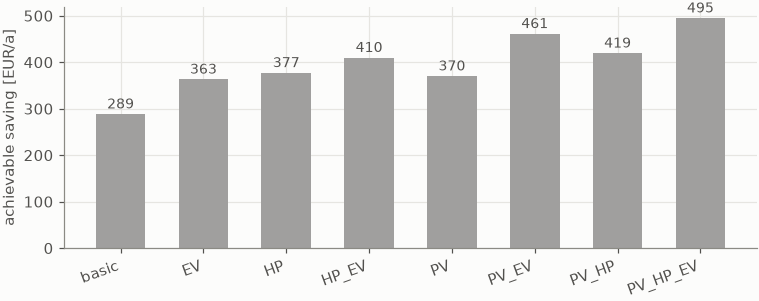

,Achievable_EUR,No_Battery_EUR
Dataset,,
Fluvius,289.0,489.0
Fluvius_EV,363.0,1110.0
Fluvius_HP,377.0,1692.0
Fluvius_HP_EV,410.0,1873.0
Fluvius_PV,370.0,260.0
Fluvius_PV_EV,461.0,758.0
Fluvius_PV_HP,419.0,798.0
Fluvius_PV_HP_EV,495.0,1335.0


In [21]:
# What each group had to gain in the first place, so a large gap can be read
# against the size of the prize rather than in isolation.
prize = (cross[cross["Controller"] == "milp_full_period"]
         .groupby("Dataset")
         .agg(Achievable_EUR=("Achievable_EUR", "mean"),
              No_Battery_EUR=("No_Battery_EUR", "mean"))
         .reindex(DATASET_GROUPS))

fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.42))
x = np.arange(len(prize))
bars = ax.bar(x, prize["Achievable_EUR"], width=0.6,
              color=pf.mix(FAMILY_COLOR["reference"], "#ffffff", 0.45))
ax.set_xticks(x, [group_label(g) for g in prize.index], rotation=20, ha="right")
bar_labels(ax, bars, list(prize["Achievable_EUR"]), fmt="{:,.0f}", horizontal=False)
finish(ax, title="What perfect foresight is worth to each household type",
       ylabel="achievable saving [EUR/a]", yfmt=EUR)
pf.show(fig, "achievable_by_household_type")
display(prize.round(0))

## 7. Pricing contract

Two things to keep apart here.

**Eligibility is not a tariff result.** Redni 2T is that supplier's plain supply list, and it
publishes no two-tariff samooskrba product, so a household with a roof cannot sign it. It is
run only against the four no-PV groups, and any figure that averages it together with the
three samooskrba lists is comparing who may sign what.

**A saving is not necessarily a battery.** A list with a wide fixed block spread — Aktivni
buys at 0.04090 and sells at 0.14990 — makes grid-to-battery arbitrage pay on its own, every
day, with no PV involved at all. That is a real saving, but it is a trading result, not a
self-consumption one, and the `Grid_Charged_kWh` share is what tells the two apart.

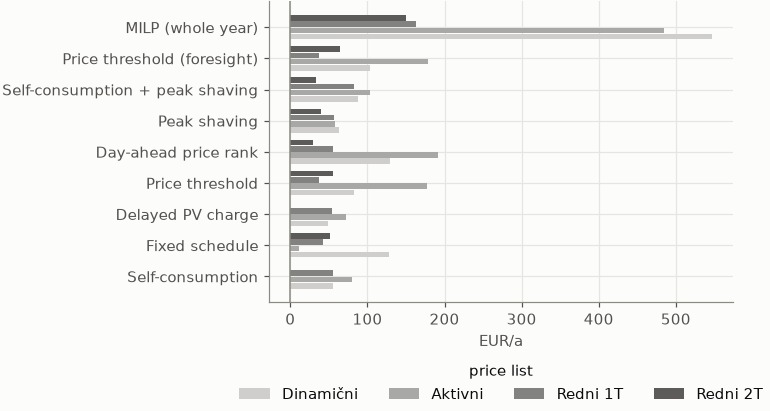

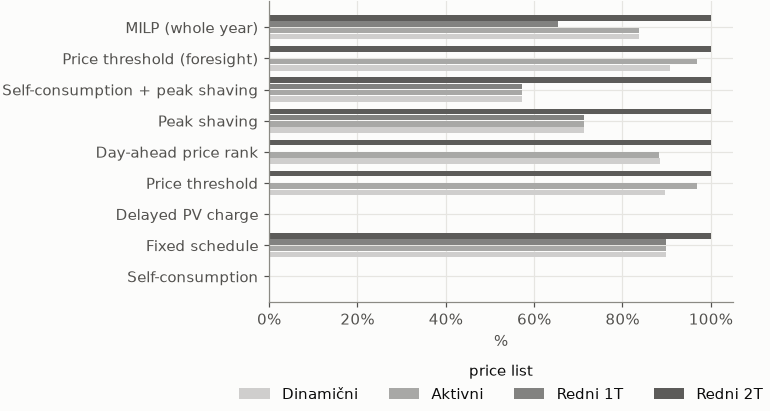

Tariff,Dinamični,Aktivni,Redni 1T,Redni 2T
Controller,,,,
self_consumption,55.0,81.0,55.0,-0.0
fixed_schedule,128.0,12.0,42.0,52.0
delayed_pv_charge,49.0,73.0,54.0,-0.0
price_threshold,83.0,178.0,38.0,56.0
price_rank_daily,129.0,191.0,55.0,30.0
peak_shaving,63.0,58.0,57.0,40.0
self_consumption_peak_shaving,88.0,104.0,82.0,34.0
price_oracle,103.0,179.0,37.0,64.0
milp_full_period,547.0,485.0,163.0,150.0


A controller that never grid-charges shows a zero-length bar on the right: self-consumption and delayed PV charge store only what the roof gave them.


In [22]:
share = (
    scored.assign(
        Grid_Share=lambda d: np.where(d["Charged_kWh"] > 1e-9,
                                      100.0 * d["Grid_Charged_kWh"] / d["Charged_kWh"],
                                      np.nan))
    .groupby(["Tariff", "Controller"])
    .agg(Saving_EUR=("Savings_EUR", "mean"),
         Grid_Share_pct=("Grid_Share", "mean"),
         Cycles=("Equivalent_Full_Cycles", "mean"))
)
grid_share = share["Grid_Share_pct"].unstack("Tariff").reindex(
    index=POLICIES + ["milp_full_period"], columns=TARIFF_ORDER)
saving = share["Saving_EUR"].unstack("Tariff").reindex(
    index=POLICIES + ["milp_full_period"], columns=TARIFF_ORDER)

y = np.arange(len(grid_share.index))
labels = [CONTROLLER_LABEL[c] for c in grid_share.index]

# One figure each: these two axes have different units and different stories,
# and side by side neither survives \columnwidth.
for frame, title, formatter, unit, export in (
    (saving, "What the battery earns", EUR, "EUR/a", "battery_earnings"),
    (grid_share, "How much of it was bought from the grid", PCT, "%", "grid_charged_share"),
):
    fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.55))
    height = 0.8 / len(TARIFF_ORDER)
    for k, tariff in enumerate(TARIFF_ORDER):
        offset = (k - (len(TARIFF_ORDER) - 1) / 2) * height
        # The price list is the SECOND categorical question these panels ask, and
        # the hue channel is already spoken for by the controller family, so it
        # gets a neutral ramp plus a legend rather than four more hues.
        ax.barh(y + offset, frame[tariff].to_numpy(dtype=float), height=height * 0.9,
                color=pf.mix(INK_2, "#ffffff", 0.72 - 0.22 * k), label=tariff)
    ax.axvline(0, color=MUTED, lw=1)
    ax.set_yticks(y, labels)
    finish(ax, title=title, xlabel=unit, xfmt=formatter)
    # Under the axes: the bars run the full width, so a legend placed inside
    # would sit on top of four of them.
    pf.key_legend(ax, [Patch(facecolor=pf.mix(INK_2, "#ffffff", 0.72 - 0.22 * k),
                             label=t) for k, t in enumerate(TARIFF_ORDER)],
                  ncol=len(TARIFF_ORDER), title="price list")
    pf.show(fig, export)

display(saving.round(0))
print("A controller that never grid-charges shows a zero-length bar on the right: "
      "self-consumption and delayed PV charge store only what the roof gave them.")

### Do two lists produce the same dispatch?

Only price *spreads* drive a battery. Two lists that sit a flat amount apart hand the
controller the same decision at every interval and therefore the same trajectory — the bills
differ, the dispatch does not. Worth checking before reading anything into two lists that
track each other.

In [23]:
dispatch = (
    scored[scored["Controller"].isin(POLICIES)]
    .pivot_table(index=["Dataset", "Household", "Capacity_kWh", "Controller"],
                 columns="Tariff", values="Discharged_kWh")
    .reindex(columns=TARIFF_ORDER)
)
pairs = []
for i, a in enumerate(TARIFF_ORDER):
    for b in TARIFF_ORDER[i + 1:]:
        both = dispatch[[a, b]].dropna()
        if both.empty:
            continue
        scale = both.to_numpy().max() or 1.0
        pairs.append({"A": a, "B": b, "Units": len(both),
                      "Max_diff_kWh": float((both[a] - both[b]).abs().max()),
                      "Rel_diff_pct": float(100.0 * (both[a] - both[b]).abs().max() / scale)})
display(pd.DataFrame(pairs).round(2).set_index(["A", "B"]))
print("Rel_diff_pct near zero means the two lists produce ONE trajectory and only "
      "the bill differs.")

Units  Max_diff_kWh  Rel_diff_pct
A         B                                          
Dinamični Aktivni    1280       1929.01         28.28
          Redni 1T   1280       6556.61         97.46
          Redni 2T    640       3321.95         49.38
Aktivni   Redni 1T   1280       6807.18         99.79
          Redni 2T    640       2512.21         36.83
Redni 1T  Redni 2T    640       5596.31         83.19

Rel_diff_pct near zero means the two lists produce ONE trajectory and only the bill differs.


## 8. Peak and the excess-power charge

The energy bill is not the only thing a battery can move. `omrežnina za presežno moč` is
charged on the running monthly peak per network block above the agreed billing power, and it
is the one part of the bill a rule can attack without knowing anything about prices — a kW
meter is enough.

It is also the line where a simple rule comes closest to the optimizer. Everywhere else the
MILP's foresight is decisive; here a controller with nothing but a kW meter lands within a few
percent of it.

The two panels disagree on purpose, and the reason is worth being precise about. The MILP
minimises the *whole* bill, so it will buy a bigger peak whenever the energy it arbitrages is
worth more than the excess charge that peak triggers — and because the charge is levied per
network block, it can push its imports into the cheap blocks and end up with the **highest
metered peak of any controller and the lowest charge for it**. A single-purpose peak shaver
makes no such trade: it holds the peak down and takes no interest in what that costs it in
energy.

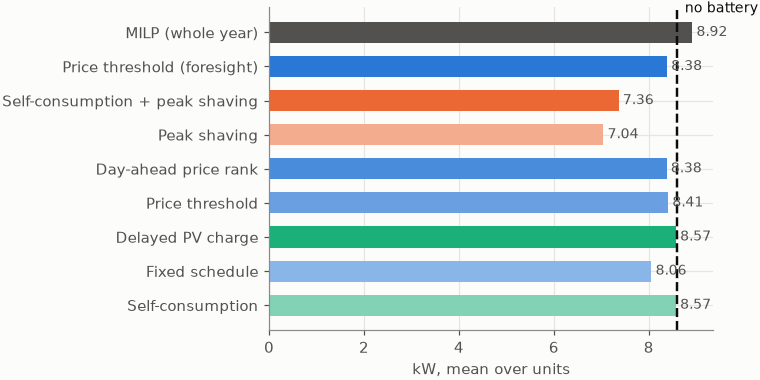

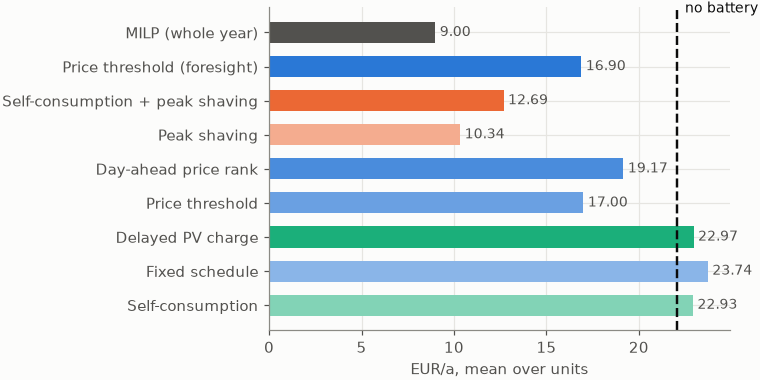

,Peak_kW,Power_EUR,Energy_EUR,Cycles
Controller,,,,
no_battery,8.59,22.06,833.23,0.00
self_consumption,8.57,22.93,784.34,39.23
fixed_schedule,8.06,23.74,826.66,215.46
delayed_pv_charge,8.57,22.97,788.27,37.98
price_threshold,8.41,17.00,737.03,133.92
price_rank_daily,8.38,19.17,725.64,149.26
peak_shaving,7.04,10.34,827.41,21.81
self_consumption_peak_shaving,7.36,12.69,792.88,44.26
price_oracle,8.38,16.90,733.41,139.21


Excess-power charge: 22.06 EUR/a with no battery, 9.00 for the MILP, 10.34 for the best rule (Peak shaving).
The rule lands within 15% of perfect foresight on this line, while giving up 79% of the saving overall — the ratchet is the one part of the bill a kW meter is nearly enough for.
It pays +248 EUR/a more than the MILP on energy to get there.
Meanwhile the MILP runs the HIGHEST metered peak of any controller (8.92 kW against 8.59 kW with no battery) and still pays the least for it — it moves its imports into the cheap network blocks. Minimising one bill line is not minimising the bill.


In [24]:
peak = (
    scored.groupby("Controller")
    .agg(Peak_kW=("Peak_Import_kW", "mean"),
         Power_EUR=("Power_EUR", "mean"),
         Energy_EUR=("Energy_EUR", "mean"),
         Cycles=("Equivalent_Full_Cycles", "mean"))
    .reindex(CONTROLLERS)
)
floor_kw = peak.loc["no_battery", "Peak_kW"]
floor_eur = peak.loc["no_battery", "Power_EUR"]

order = [c for c in CONTROLLERS if c != "no_battery"]
y = np.arange(len(order))

fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.52))
bars = ax.barh(y, peak.loc[order, "Peak_kW"], height=0.62,
               color=[controller_color(c) for c in order])
ax.axvline(floor_kw, color=INK, lw=1.6, ls="--")
# Anchored on the reference line itself, not on the axes edge -- the label is
# naming that line.
ax.text(floor_kw, len(order) - 0.3, "  no battery", color=INK, fontsize=9, va="center")
ax.set_yticks(y, [CONTROLLER_LABEL[c] for c in order])
bar_labels(ax, bars, list(peak.loc[order, "Peak_kW"]), fmt="{:.2f}")
finish(ax, title="Peak grid import — what the ratchet is measured on",
       xlabel="kW, mean over units")
pf.show(fig, "peak_grid_import")

fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.52))
bars = ax.barh(y, peak.loc[order, "Power_EUR"], height=0.62,
               color=[controller_color(c) for c in order])
ax.axvline(floor_eur, color=INK, lw=1.6, ls="--")
ax.text(floor_eur, len(order) - 0.3, "  no battery", color=INK, fontsize=9, va="center")
ax.set_yticks(y, [CONTROLLER_LABEL[c] for c in order])
bar_labels(ax, bars, list(peak.loc[order, "Power_EUR"]), fmt="{:.2f}")
finish(ax, title="Excess-power charge — the part a kW meter alone can attack",
       xlabel="EUR/a, mean over units", xfmt=EUR)
pf.show(fig, "excess_power_charge")

display(peak.round(2))

# Stated as a computed fact rather than as prose: which controller actually pays
# the least excess-power charge, and what it gave up elsewhere to get there.
best_rule_on_power = peak.loc[POLICIES, "Power_EUR"].idxmin()
milp_power = peak.loc["milp_full_period", "Power_EUR"]
rule_power = peak.loc[best_rule_on_power, "Power_EUR"]
print(f"Excess-power charge: {peak.loc['no_battery', 'Power_EUR']:.2f} EUR/a with no battery, "
      f"{milp_power:.2f} for the MILP, {rule_power:.2f} for the best rule "
      f"({CONTROLLER_LABEL[best_rule_on_power]}).")
print(f"The rule lands within {abs(rule_power - milp_power) / max(milp_power, 1e-9):.0%} of "
      f"perfect foresight on this line, while giving up "
      f"{ranking.loc[best_rule_on_power, 'Gap_pct']:.0f}% of the saving overall — "
      f"the ratchet is the one part of the bill a kW meter is nearly enough for.")
print(f"It pays {peak.loc[best_rule_on_power, 'Energy_EUR'] - peak.loc['milp_full_period', 'Energy_EUR']:+,.0f} "
      f"EUR/a more than the MILP on energy to get there.")
print(f"Meanwhile the MILP runs the {'HIGHEST' if peak.loc['milp_full_period', 'Peak_kW'] == peak['Peak_kW'].max() else 'a lower'} "
      f"metered peak of any controller ({peak.loc['milp_full_period', 'Peak_kW']:.2f} kW against "
      f"{peak.loc['no_battery', 'Peak_kW']:.2f} kW with no battery) and still pays the least for "
      f"it — it moves its imports into the cheap network blocks. Minimising one bill line is "
      f"not minimising the bill.")

## 9. Verification

Four claims this notebook rests on, checked against the results themselves rather than
asserted in prose. The module-level invariants — the envelope, the re-pricing, the daily cycle
cap — live in `Rule_Based_Control_Check.py`:

```
.venv/bin/python Rule_Based_Control_Check.py
```

In [25]:
### Verification 1 — the MILP is a lower bound on every rule
# The MILP minimises the same bill over the same battery with perfect foresight,
# so no rule may come in under it. A rule that does is not controlling better,
# it is being priced differently, and every number above would be void.
tolerance = scored["Optimum_EUR"].abs() * SOLVER_GAP_REL + 1e-6
under = scored[scored["Gap_to_Optimum_EUR"] < -tolerance]
assert under.empty, (
    f"{len(under)} rows beat the perfect-foresight optimum by more than the "
    f"{SOLVER_GAP_REL:.0e} MIP gap:\n{under.head()}"
)
print(f"Verification 1 OK — all {len(scored):,} rows at or above the optimum "
      f"(worst undershoot {scored['Gap_to_Optimum_EUR'].min():+.4f} EUR, "
      f"within the {SOLVER_GAP_REL:.0e} MIP gap)")

Verification 1 OK — all 5,600 rows at or above the optimum (worst undershoot +0.0000 EUR, within the 1e-03 MIP gap)


In [26]:
### Verification 2 — every rule respected the battery envelope
# The runner clamps every setpoint to the feasible bounds before executing it,
# so a rule cannot drift the state of charge at all. The MILP arm is held to a
# looser bar on purpose: it stops at its MIP gap, and a solution that is optimal
# to 0.1 % can land a few micro-kWh outside the SOC bound.
rules_drift = scored[scored["Controller"].isin(POLICIES)]["SOC_Drift_kWh"].abs().max()
milp_drift = scored[scored["Controller"] == "milp_full_period"]["SOC_Drift_kWh"].abs().max()
assert rules_drift < 1e-9, f"a rule drifted the state of charge by {rules_drift:.2e} kWh"
assert milp_drift < 1e-3, f"the MILP arm drifted {milp_drift:.2e} kWh, beyond solver noise"

# No rule curtails, so the whole PV yield is either used, stored or exported.
curtailed = scored[scored["Controller"].isin(POLICIES)]["Curtailed_kWh"].abs().max()
assert curtailed < 1e-9, f"a rule curtailed {curtailed:.4f} kWh"
print(f"Verification 2 OK — rules drifted {rules_drift:.1e} kWh (clamped by the runner), "
      f"MILP {milp_drift:.1e} kWh (solver noise), no rule curtailed ({curtailed:.1e} kWh)")

Verification 2 OK — rules drifted 4.4e-16 kWh (clamped by the runner), MILP 1.5e-05 kWh (solver noise), no rule curtailed (0.0e+00 kWh)


In [27]:
### Verification 3 — the references are consistent across a unit
# `No_Battery_EUR` is a property of the household, the list and the year, so it
# must not vary with the capacity or the controller within one household-list.
spread = (
    scored.groupby(["Dataset", "Household", "Tariff"])["No_Battery_EUR"]
    .agg(lambda s: s.max() - s.min()).max()
)
assert spread < 1e-6, f"the no-battery baseline varies by {spread:.6f} EUR within a unit"

# And self-consumption may never have touched the grid, on any household.
grid = scored[scored["Controller"] == "self_consumption"]["Grid_Charged_kWh"].abs().max()
assert grid < 1e-9, f"self_consumption grid-charged {grid:.4f} kWh"
print(f"Verification 3 OK — baseline constant within each unit ({spread:.1e} EUR), "
      f"self-consumption never grid-charged ({grid:.1e} kWh)")

Verification 3 OK — baseline constant within each unit (0.0e+00 EUR), self-consumption never grid-charged (0.0e+00 kWh)


In [28]:
### Verification 4 — foresight, and nothing else, separates the two threshold rules
# `price_oracle` is `price_threshold` with the window pointed forward. Same rule,
# same quantiles, same breakeven gate. If the forward version were not at least
# as good, the pair would not be isolating foresight.
pair = (scored[scored["Controller"].isin(["price_threshold", "price_oracle"])]
        .pivot_table(index=rbc.KEY_COLUMNS, columns="Controller",
                     values="Cost_EUR_Closed").dropna())
worse = pair[pair["price_oracle"] > pair["price_threshold"] + 1e-6]
gain = pair["price_threshold"] - pair["price_oracle"]
# Foresight helps ON AVERAGE, and that is all that can be asserted. A threshold
# rule is a heuristic, not an optimizer: feeding it better information moves its
# thresholds, and a moved threshold is not guaranteed to be a better one. That
# the forward window loses on a minority of units is a property of the RULE, not
# a defect in the experiment -- and it is itself the finding, because it says the
# gap to the MILP is mostly the shape of the rule rather than the horizon.
assert gain.mean() > 0, (
    f"the forward window is worth {gain.mean():+.4f} EUR/a on average — the pair "
    f"is not isolating foresight"
)
print(f"Verification 4 OK — foresight is worth {gain.mean():+.2f} EUR/a on average "
      f"({gain.min():+.2f} .. {gain.max():+.2f} across units)")
print(f"  but it LOST on {len(worse)} of {len(pair)} units ({len(worse)/len(pair):.0%}): "
      f"better information moves a heuristic's thresholds, it does not sharpen its logic.")

Verification 4 OK — foresight is worth +7.24 EUR/a on average (-9.78 .. +70.42 across units)
  but it LOST on 133 of 560 units (24%): better information moves a heuristic's thresholds, it does not sharpen its logic.


## 10. Read-out

In [29]:
rules_only = ranking.loc[POLICIES]
best = rules_only["Gap_pct"].idxmin()
worst = rules_only["Gap_pct"].idxmax()
causal_rules = [c for c in POLICIES if rbc.make_policy(c).causal]
best_causal = rules_only.loc[causal_rules, "Gap_pct"].idxmin()
foresight = (rules_only.loc["price_threshold", "Savings_EUR"]
             - rules_only.loc["price_oracle", "Savings_EUR"])
milp_row = rbc.summarize(cross, by=["Controller"])[0].loc["milp_full_period"]
peak_best = peak.loc[POLICIES, "Peak_kW"].idxmin()
cap_first, cap_last = CAPACITIES_KWH[0], CAPACITIES_KWH[-1]

lines = [
    f"{len(units):,} complete units: {units['Dataset'].nunique()} Fluvius groups x "
    f"{PER_GROUP} households x {len(TARIFF_ORDER)} price lists x "
    f"{len(CAPACITIES_KWH)} capacities, one calendar year each.",
    "",
    f"The whole-year MILP saves {milp_row['Savings_EUR']:,.0f} EUR/a on average. That is the "
    f"prize; every percentage below is a share of it.",
    "",
    f"Best deployable rule: {CONTROLLER_LABEL[best_causal]}, giving up "
    f"{rules_only.loc[best_causal, 'Gap_pct']:.0f}% of the achievable saving "
    f"({rules_only.loc[best_causal, 'Savings_EUR']:,.0f} EUR/a of "
    f"{milp_row['Savings_EUR']:,.0f}). Weighted by the euros at stake rather than by "
    f"household it gives up {rules_only.loc[best_causal, 'Gap_pct_pooled']:.0f}%.",
    f"Worst rule: {CONTROLLER_LABEL[worst]}, at "
    f"{rules_only.loc[worst, 'Gap_pct']:.0f}%.",
    f"Spread across the eight rules: {rules_only['Gap_pct'].min():.0f}% to "
    f"{rules_only['Gap_pct'].max():.0f}% — the choice of rule is worth "
    f"{rules_only['Savings_EUR'].max() - rules_only['Savings_EUR'].min():,.0f} EUR/a.",
    "",
    f"Foresight, isolated: pointing the same threshold rule's window forward instead of "
    f"backward is worth {-foresight:,.0f} EUR/a. Everything else in the gap to the MILP is "
    f"the shape of the rule, not the horizon it sees.",
    "",
    f"Pack size: the mean gap moves from "
    f"{gap_by_cap.loc[cap_first].mean():.0f}% at {cap_first:g} kWh to "
    f"{gap_by_cap.loc[cap_last].mean():.0f}% at {cap_last:g} kWh. A bigger battery is a "
    f"longer lever on a future a rule cannot see, so the rules fall further behind as it "
    f"grows.",
    "",
    f"Peak power: {CONTROLLER_LABEL[peak_best]} holds the mean peak to "
    f"{peak.loc[peak_best, 'Peak_kW']:.2f} kW against "
    f"{peak.loc['no_battery', 'Peak_kW']:.2f} kW with no battery, and the excess-power "
    f"charge from {peak.loc['no_battery', 'Power_EUR']:.2f} to "
    f"{peak.loc[peak_best, 'Power_EUR']:.2f} EUR/a. That part of the bill needs a kW meter, "
    f"not a price forecast.",
]
print("\n".join(lines))

560 complete units: 8 Fluvius groups x 5 households x 4 price lists x 4 capacities, one calendar year each.

The whole-year MILP saves 398 EUR/a on average. That is the prize; every percentage below is a share of it.

Best deployable rule: Day-ahead price rank, giving up 69% of the achievable saving (125 EUR/a of 398). Weighted by the euros at stake rather than by household it gives up 69%.
Worst rule: Fixed schedule, at 85%.
Spread across the eight rules: 69% to 85% — the choice of rule is worth 67 EUR/a.

Foresight, isolated: pointing the same threshold rule's window forward instead of backward is worth 7 EUR/a. Everything else in the gap to the MILP is the shape of the rule, not the horizon it sees.

Pack size: the mean gap moves from 74% at 5 kWh to 81% at 30 kWh. A bigger battery is a longer lever on a future a rule cannot see, so the rules fall further behind as it grows.

Peak power: Peak shaving holds the mean peak to 7.04 kW against 8.59 kW with no battery, and the excess-powe

### Caveats

- **Terminal state of charge.** Every MILP strategy is pinned to start *and* end the year at
  50 % of capacity; a rule has no terminal constraint. `Cost_EUR_Closed` — the figure every
  comparison above uses — values the shortfall at the mean delivered import rate, so a rule
  that runs the pack down in December cannot book the difference as a saving. `Cost_EUR` is
  kept in the results so the size of that adjustment stays visible.

- **Curtailment is asymmetric.** The MILP may spill PV for free; no rule here does, matching
  the no-battery baseline, which also curtails nothing. `Curtailed_kWh` is reported for both
  (verification 2). Where the MILP spills, part of its advantage is an option the rules were
  not given.

- **`price_oracle` is not a controller.** It reads seven days of future prices. It exists only
  to separate "the rule is too simple" from "the rule cannot see ahead", and it should never
  appear in a recommendation.

- **`delayed_pv_charge` is solving a problem this market does not have.** Feed-in damping was
  designed for a hard export cap (the German 70 % rule), where surplus not stored is surplus
  destroyed. Under `si_samooskrba` every exported kWh is credited, so holding back the morning
  only means exporting the cheaper midday instead. The result is a fair reading of the rule
  under this settlement, not of the rule in general.

- **Redni 2T covers different households.** It is a no-PV-only product, excluded from every
  cross-group figure (chapters 4–6, 8) and reported on its own in chapter 7.

- **One year, borrowed calendar.** Belgian Fluvius profiles for 2024 priced under the 2026
  Slovenian tariff regime. The stamps carry a `Z` suffix but are Brussels-local, which is why
  every clock rule and every daily budget here reads local time through `si_cas.v_lokalni_cas`
  rather than off the index.

- **Agreed billing power is endogenous.** Each month's dogovorjena moč is re-agreed from the
  peaks the *controller's own* metered profile realized the month before, at a one-month lag —
  the household re-contracts down to whatever its battery leaves it drawing, and is then billed
  against that line. Every controller therefore pays a different power charge, and the
  no-battery reference keeps the no-battery contract, which is its own. The MILP settles its
  contract inside the LP (`add_endogenous_agreed_power`), so it is still the exact optimum and
  still a lower bound; the rules reach theirs by re-running to a fixed point.

- **The rules are untuned.** Every threshold, window and reserve is a stated default, not a
  fitted parameter. Tuning them per household would narrow the gap to the MILP and would also
  stop being a rule-based controller.